# Análisis exploratorio de los embeddings — Geohelmintos en microscopía

Proyecto final de Machine Learning y de Redes Neuronales y Deep Learning (EAFIT 2026-2). Equipo:
Samuel Llano Madrigal, Laura Andrea Castrillon y Jerónimo Campuzano.

**Objetivo.** Conocer el espacio de los embeddings de DINOv2 antes de entrenar modelos: si los vectores están
sanos, cuántas dimensiones importan, si las especies se ven separadas, cuáles se parecen entre sí, si hay
recortes atípicos o con etiqueta dudosa, y si el embedding guarda pistas que no son del huevo (atajos). Es un
análisis **descriptivo**: no se entrena ningún clasificador ni se ajustan hiperparámetros (eso es del
modelado de la rama ML).

**Datos.** Un vector de 768 números por huevo recortado (DINOv2 ViT-B/14), en dos versiones: `cls` (el resumen
global estándar) y `patch_mean` (el promedio de los parches). Los 2749 recortes salen de las cajas dibujadas
en Chula (`crop_eggs.py`), con margen de 15 %. Al final se contrastan con los 425 recortes que encontró YOLO en
`valid`.

**Partición.** La del equipo (70/15/15 por foto original, seed 42). El inventario muestra las tres, pero todo
lo demás usa solo `train` y `valid`: `test` está congelado. El escalado y el PCA se ajustan solo con `train`.

**Cómo correrlo.** Desde la raíz del repo, después de `scripts/apolo/prepare_ml.sh`, con el kernel
`Python (geohelmintos)`. Sin GPU.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from PIL import Image
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler

In [2]:
ROOT = Path.cwd() if (Path.cwd() / "src").is_dir() else Path.cwd().parent
EMBEDDINGS_NPZ = ROOT / "artifacts" / "embeddings" / "dinov2_vitb14_224.npz"
CROPS_CSV = ROOT / "data" / "crops" / "crops.csv"
YOLO_EMBEDDINGS_NPZ = ROOT / "artifacts" / "embeddings_detected" / "valid" / "dinov2_vitb14_224.npz"
YOLO_CROPS_CSV = ROOT / "artifacts" / "detected" / "valid" / "crops.csv"
assert all(p.is_file() for p in (EMBEDDINGS_NPZ, CROPS_CSV, YOLO_EMBEDDINGS_NPZ, YOLO_CROPS_CSV)), \
    "run scripts/apolo/prepare_ml.sh first"

CLASSES = ["ascaris", "hookworm", "trichuris"]
SPLITS = ["train", "valid", "test"]
SPLITS_USED = ["train", "valid"]  # test stays frozen: nothing below uses it
SEED = 42
N_NEIGHBORS = 10          # neighbors looked at for every crop
N_COMPONENTS_SHOWN = 10   # principal components compared with the pixel statistics
N_COMPONENTS_FOR_TSNE = 50

# Same palette as eda_dataset.ipynb; extra colors for splits and for the YOLO groups of section 9
COLORS = {"ascaris": "#2a78d6", "hookworm": "#eb6834", "trichuris": "#1baf7a"}
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8a8984", "#e6e5e1", "#fcfcfb"
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#fcfcfb", "#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"])
SPLIT_COLORS = {"train": "#c9c8c3", "valid": INK}
YOLO_GROUP_COLORS = {"Hand-drawn box": MUTED, "YOLO box, egg": INK2, "YOLO box, false alarm": "#b3261e"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 100, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.titlelocation": "left", "text.color": INK, "axes.labelcolor": INK2,
    "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})
pd.set_option("display.precision", 3)

In [3]:
def load_embeddings(npz_path, crops_csv_path):
    """Crop metadata (one row per crop) and the two embedding matrices, in the same order."""
    data = np.load(npz_path, allow_pickle=True)  # our own file: it stores the strings as objects
    crops = pd.read_csv(crops_csv_path)
    assert len(crops) == len(data["cls"]), "npz and crops.csv have a different number of crops"
    assert (crops.crop_path.to_numpy() == data["crop_paths"]).all(), "npz and crops.csv are not aligned"
    return crops, data["cls"], data["patch_mean"]


def to_unit(vectors):
    """Scale every vector to length 1, so that a dot product is the cosine similarity."""
    return vectors / np.linalg.norm(vectors, axis=1, keepdims=True)


def show_crop(ax, crop_path, title):
    ax.imshow(Image.open(ROOT / crop_path))
    ax.set_title(title, fontsize=8, loc="center", fontweight="normal")
    ax.axis("off")


def draw_heatmap(ax, values, title, annotations=None, vmin=None, vmax=None):
    """A table as a heatmap with its numbers written in the cells (darker = larger)."""
    numbers = values.to_numpy(dtype=float)
    vmin = numbers.min() if vmin is None else vmin
    vmax = numbers.max() if vmax is None else vmax
    ax.imshow(numbers, cmap=BLUES, vmin=vmin, vmax=vmax, aspect="auto")
    shown = values if annotations is None else annotations
    for (row, col), number in np.ndenumerate(shown.to_numpy(dtype=float)):
        darkness = (numbers[row, col] - vmin) / (vmax - vmin) if vmax > vmin else 0
        ax.text(col, row, f"{number:.2f}", ha="center", va="center", fontsize=9,
                color=SURFACE if darkness > 0.6 else INK)
    ax.set_xticks(range(values.shape[1]), values.columns, rotation=30, ha="right")
    ax.set_yticks(range(values.shape[0]), values.index)
    ax.set_title(title)
    ax.grid(False)


all_crops, all_cls, all_patch_mean = load_embeddings(EMBEDDINGS_NPZ, CROPS_CSV)
print(f"{len(all_crops)} crops loaded from {EMBEDDINGS_NPZ.relative_to(ROOT)}")

2749 crops loaded from artifacts/embeddings/dinov2_vitb14_224.npz


## 1. Inventario

Cuántos recortes hay por clase y partición, y el tamaño de las matrices. Desde aquí se deja fuera `test`:
`crops` y los vectores `cls_vectors` y `patch_mean_vectors` solo contienen `train` y `valid`.

In [4]:
def with_totals(table):
    table = table.reindex(index=SPLITS, columns=CLASSES)
    table["total"] = table.sum(axis=1)
    table.loc["total"] = table.sum()
    return table


display(with_totals(pd.crosstab(all_crops.split, all_crops.label)).rename_axis(index="crops", columns=None))
print("Matrix shapes:", {"cls": all_cls.shape, "patch_mean": all_patch_mean.shape})
print("Photos with more than one crop:", int((all_crops.group.value_counts() > 1).sum()))

is_used = all_crops.split.isin(SPLITS_USED).to_numpy()
crops = all_crops[is_used].reset_index(drop=True)
cls_vectors, patch_mean_vectors = all_cls[is_used], all_patch_mean[is_used]
is_train = (crops.split == "train").to_numpy()
labels = crops.label.to_numpy()
group_ids = pd.factorize(crops.group)[0]  # one integer per original photo
print(f"Used from here on: {len(crops)} crops ({', '.join(SPLITS_USED)}); test is left out")

,ascaris,hookworm,trichuris,total
crops,,,,
train,636,650,638,1924
valid,136,140,137,413
test,138,138,136,412
total,910,928,911,2749


Matrix shapes: {'cls': (2749, 768), 'patch_mean': (2749, 768)}
Photos with more than one crop: 18
Used from here on: 2337 crops (train, valid); test is left out


## 2. Integridad

Se revisa que no haya valores nulos o infinitos, que ninguna foto original quede repartida entre particiones y
cómo es la longitud (norma) de los vectores. Después, la comprobación que más importa: si algún recorte de
`valid` es casi idéntico a uno de `train`, las métricas saldrían infladas. Para cada recorte de `valid` se busca
su recorte más parecido de `train` (similitud coseno: 1 = misma dirección). Se muestran las parejas más parecidas
para revisarlas a ojo.

NaN values: 0
Infinite values: 0
Photos spread over more than one split: 0


cls                     patch_mean                    
            mean   std    min    max       mean   std    min    max
label                                                              
ascaris    48.60  0.63  43.66  50.33      32.61  1.73  26.10  37.91
hookworm   48.57  0.89  40.61  50.07      33.03  1.61  27.00  37.64
trichuris  48.58  0.94  38.70  49.95      33.24  1.93  25.92  38.05

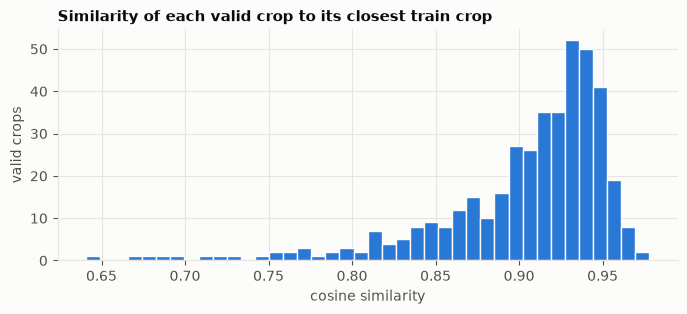

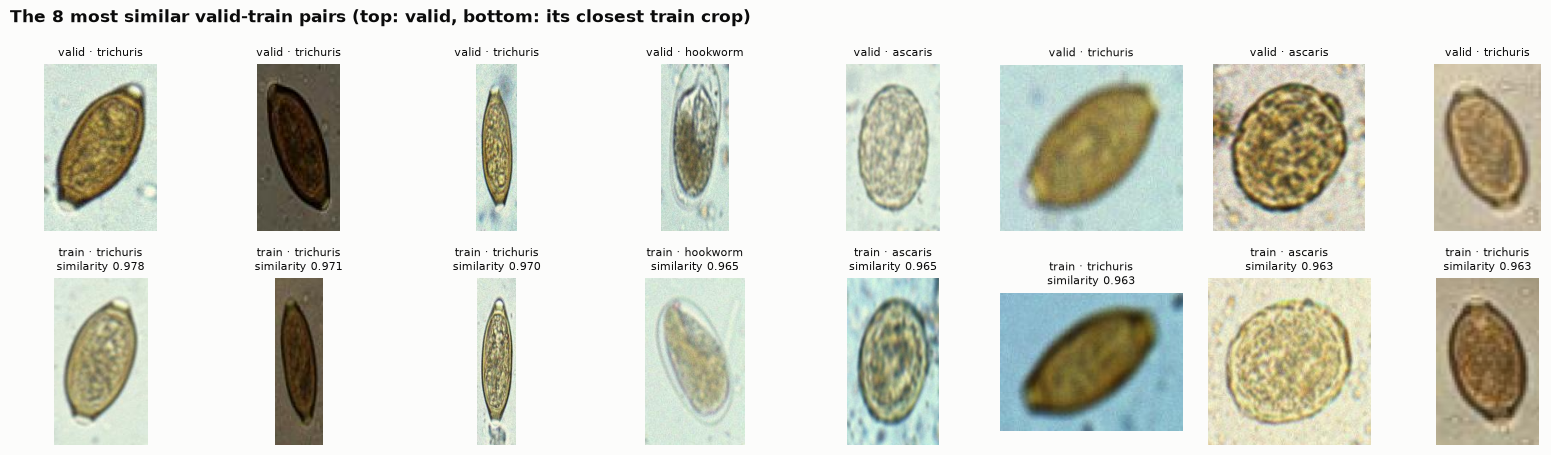

In [5]:
print("NaN values:", int(np.isnan(cls_vectors).sum() + np.isnan(patch_mean_vectors).sum()))
print("Infinite values:", int(np.isinf(cls_vectors).sum() + np.isinf(patch_mean_vectors).sum()))
print("Photos spread over more than one split:",
      int((all_crops.groupby("group").split.nunique() > 1).sum()))

norms = pd.DataFrame({"cls": np.linalg.norm(cls_vectors, axis=1),
                      "patch_mean": np.linalg.norm(patch_mean_vectors, axis=1),
                      "label": labels})
display(norms.groupby("label").agg(["mean", "std", "min", "max"]).round(2))

# Closest train crop of every valid crop
unit_cls = to_unit(cls_vectors)
valid_crops = crops[~is_train].reset_index(drop=True)
train_crops = crops[is_train].reset_index(drop=True)
similarity_valid_to_train = unit_cls[~is_train] @ unit_cls[is_train].T
closest_train = similarity_valid_to_train.argmax(axis=1)
closest_similarity = similarity_valid_to_train.max(axis=1)

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(closest_similarity, bins=40, color=COLORS["ascaris"], edgecolor=SURFACE, linewidth=1)
ax.set(title="Similarity of each valid crop to its closest train crop",
       xlabel="cosine similarity", ylabel="valid crops")
plt.show()

most_similar_pairs = np.argsort(-closest_similarity)[:8]
fig, axes = plt.subplots(2, len(most_similar_pairs), figsize=(2.0 * len(most_similar_pairs), 4.6))
for col, valid_index in enumerate(most_similar_pairs):
    train_index = closest_train[valid_index]
    show_crop(axes[0, col], valid_crops.crop_path[valid_index], f"valid · {valid_crops.label[valid_index]}")
    show_crop(axes[1, col], train_crops.crop_path[train_index],
              f"train · {train_crops.label[train_index]}\nsimilarity {closest_similarity[valid_index]:.3f}")
fig.suptitle("The 8 most similar valid-train pairs (top: valid, bottom: its closest train crop)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

## 3. Dimensionalidad

Cada vector tiene 768 números, pero no todos aportan lo mismo. El **PCA** (análisis de componentes principales)
ordena las direcciones del espacio de mayor a menor variación. La curva muestra cuánta de la variación total
queda explicada con los primeros componentes. Se estandariza cada dimensión y el PCA se ajusta **solo con
`train`**; `valid` se proyecta con lo aprendido ahí.

Components needed (cls): {'80%': 68, '90%': 151, '95%': 253, '99%': 486}
Variance of the first 5 components: [0.126 0.079 0.067 0.056 0.038]


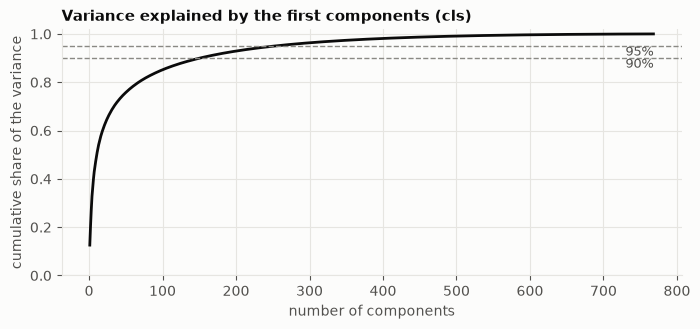

In [6]:
def fit_pca(vectors):
    """Standardize and run PCA fitted on the train crops only; returns the PCA and every crop's coordinates."""
    scaler = StandardScaler().fit(vectors[is_train])
    pca = PCA(random_state=SEED).fit(scaler.transform(vectors[is_train]))
    return pca, pca.transform(scaler.transform(vectors))


def components_needed(pca, share):
    """How many components explain at least `share` of the total variance."""
    return int(np.searchsorted(np.cumsum(pca.explained_variance_ratio_), share) + 1)


cls_pca, cls_components = fit_pca(cls_vectors)
print("Components needed (cls):", {f"{share:.0%}": components_needed(cls_pca, share)
                                  for share in (0.80, 0.90, 0.95, 0.99)})
print("Variance of the first 5 components:", np.round(cls_pca.explained_variance_ratio_[:5], 3))

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(np.arange(1, len(cls_pca.explained_variance_ratio_) + 1),
        np.cumsum(cls_pca.explained_variance_ratio_), color=INK, linewidth=2)
for share in (0.90, 0.95):
    ax.axhline(share, color=MUTED, linestyle="--", linewidth=1)
    ax.text(len(cls_pca.explained_variance_ratio_), share - 0.04, f"{share:.0%}", ha="right", fontsize=9, color=INK2)
ax.set(title="Variance explained by the first components (cls)",
       xlabel="number of components", ylabel="cumulative share of the variance", ylim=(0, 1.02))
plt.show()

## 4. Mapas en 2D

Dos formas de dibujar los vectores en un plano: los **dos primeros componentes del PCA** (conserva las
distancias grandes) y **t-SNE** (acerca los vecinos y suele separar mejor los grupos, pero sus distancias
grandes no significan nada). Cada fila de la figura usa un método y cada columna un color: por especie (¿se ven
grupos?) y por partición (¿`valid` cae entre los de `train`?). Que un mapa 2D no separe las especies no prueba
que no se puedan separar: se pierde información al pasar de 768 dimensiones a 2.

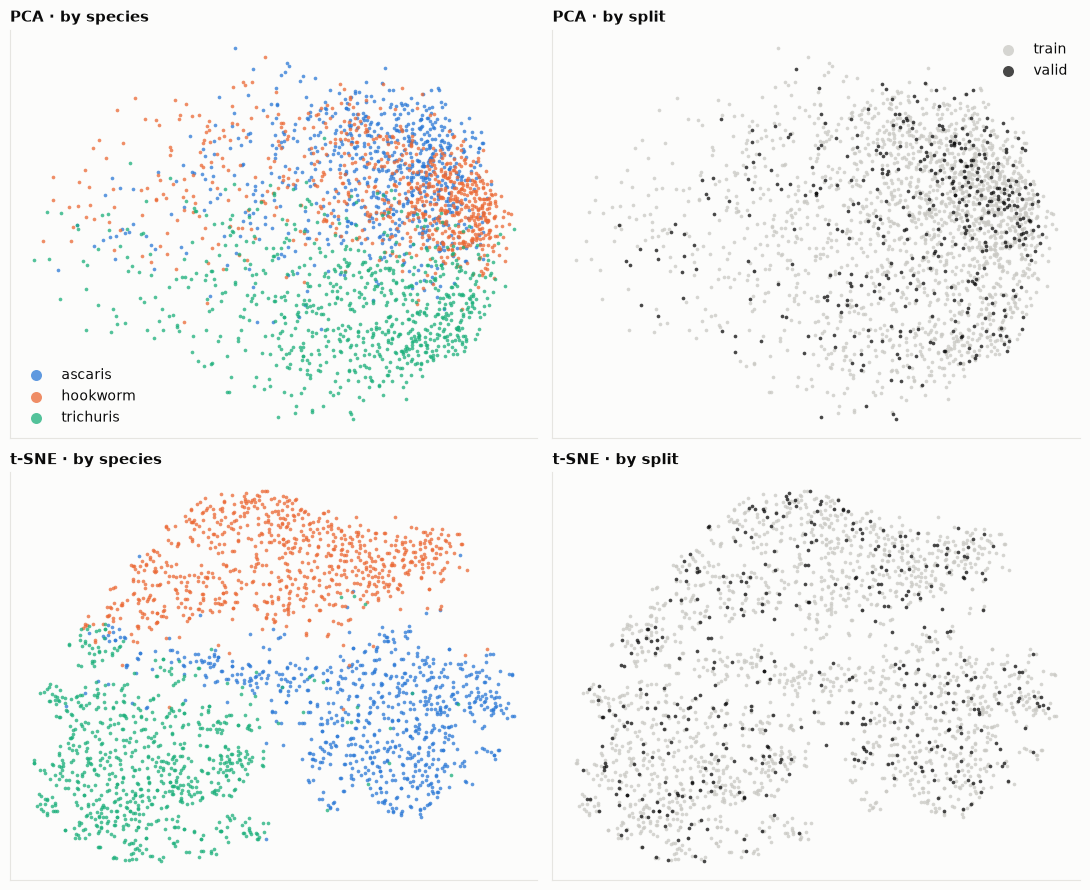

In [7]:
def scatter_groups(ax, coordinates, values, colors, title):
    for value, color in colors.items():
        mask = values == value
        ax.scatter(coordinates[mask, 0], coordinates[mask, 1], s=7, color=color, alpha=0.75,
                   linewidths=0, label=value)
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)


tsne_coordinates = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEED).fit_transform(
    cls_components[:, :N_COMPONENTS_FOR_TSNE])
pca_coordinates = cls_components[:, :2]

splits = crops.split.to_numpy()
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
for row, (method, coordinates) in enumerate([("PCA", pca_coordinates), ("t-SNE", tsne_coordinates)]):
    scatter_groups(axes[row, 0], coordinates, labels, COLORS, f"{method} · by species")
    scatter_groups(axes[row, 1], coordinates, splits, SPLIT_COLORS, f"{method} · by split")
axes[0, 0].legend(markerscale=3)
axes[0, 1].legend(markerscale=3)
plt.tight_layout()
plt.show()

## 5. Similitud entre especies y vecinos más cercanos

- **Similitud media:** el promedio de la similitud coseno entre los recortes de cada par de especies. Si la
  diagonal (misma especie) es mucho mayor que lo demás, las especies forman grupos; si dos especies se parecen
  entre sí casi tanto como a sí mismas, son las que el modelo va a confundir.
- **Vecinos:** para cada recorte se buscan los `N_NEIGHBORS` más parecidos (sin contar recortes de su misma foto,
  porque serían trivialmente parecidos). La tabla dice, para cada especie, qué parte de sus vecinos es de cada
  especie. La diagonal es la **pureza** de los vecinos.

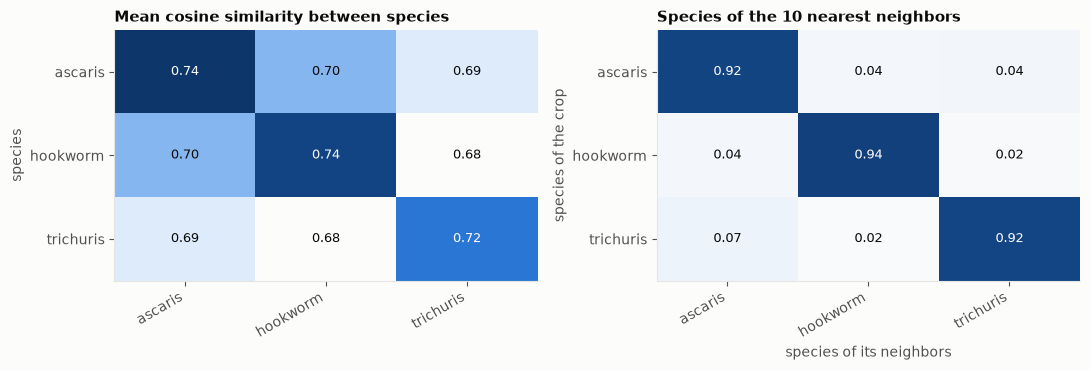

Neighbor purity per species: {'ascaris': 0.923, 'hookworm': 0.944, 'trichuris': 0.917}


In [8]:
def class_similarity_matrix(unit_vectors):
    """Mean cosine similarity between the crops of class a and of class b (a crop is never compared with itself)."""
    matrix = pd.DataFrame(index=CLASSES, columns=CLASSES, dtype=float)
    for class_a in CLASSES:
        for class_b in CLASSES:
            similarity = unit_vectors[labels == class_a] @ unit_vectors[labels == class_b].T
            if class_a == class_b:
                n_crops = similarity.shape[0]
                matrix.loc[class_a, class_b] = (similarity.sum() - n_crops) / (n_crops * (n_crops - 1))
            else:
                matrix.loc[class_a, class_b] = similarity.mean()
    return matrix


def nearest_neighbors(unit_vectors, k):
    """The k most similar crops of every crop, ignoring crops of the same photo (and the crop itself)."""
    similarity = unit_vectors @ unit_vectors.T
    similarity[group_ids[:, None] == group_ids[None, :]] = -np.inf
    neighbors = np.argpartition(-similarity, k, axis=1)[:, :k]
    return neighbors, similarity


def neighbor_share(neighbors):
    """For each species (rows): share of its crops' neighbors that belong to each species (columns)."""
    neighbor_labels = labels[neighbors]
    share = pd.DataFrame({name: (neighbor_labels == name).mean(axis=1) for name in CLASSES})
    return share.groupby(labels).mean().reindex(CLASSES)


cls_neighbors, cls_similarity = nearest_neighbors(unit_cls, N_NEIGHBORS)
class_similarity = class_similarity_matrix(unit_cls)
cls_neighbor_share = neighbor_share(cls_neighbors)

fig, (ax_similarity, ax_neighbors) = plt.subplots(1, 2, figsize=(11, 3.8))
draw_heatmap(ax_similarity, class_similarity, "Mean cosine similarity between species")
draw_heatmap(ax_neighbors, cls_neighbor_share, f"Species of the {N_NEIGHBORS} nearest neighbors", vmin=0, vmax=1)
ax_similarity.set_ylabel("species")
ax_neighbors.set_ylabel("species of the crop")
ax_neighbors.set_xlabel("species of its neighbors")
plt.tight_layout()
plt.show()
print("Neighbor purity per species:", {name: round(float(cls_neighbor_share.loc[name, name]), 3) for name in CLASSES})

## 6. Ejemplos a ojo

- **Vecinos:** tres recortes al azar de cada especie (con la seed del proyecto) y sus 5 vecinos más parecidos.
  Sirve para ver qué entiende el embedding por "parecido".
- **Atípicos:** los recortes cuyos vecinos son casi todos de otra especie. Pueden ser huevos ambiguos o
  etiquetas dudosas. No se corrigen a mano: se anotan para que un experto de la UPB los revise.

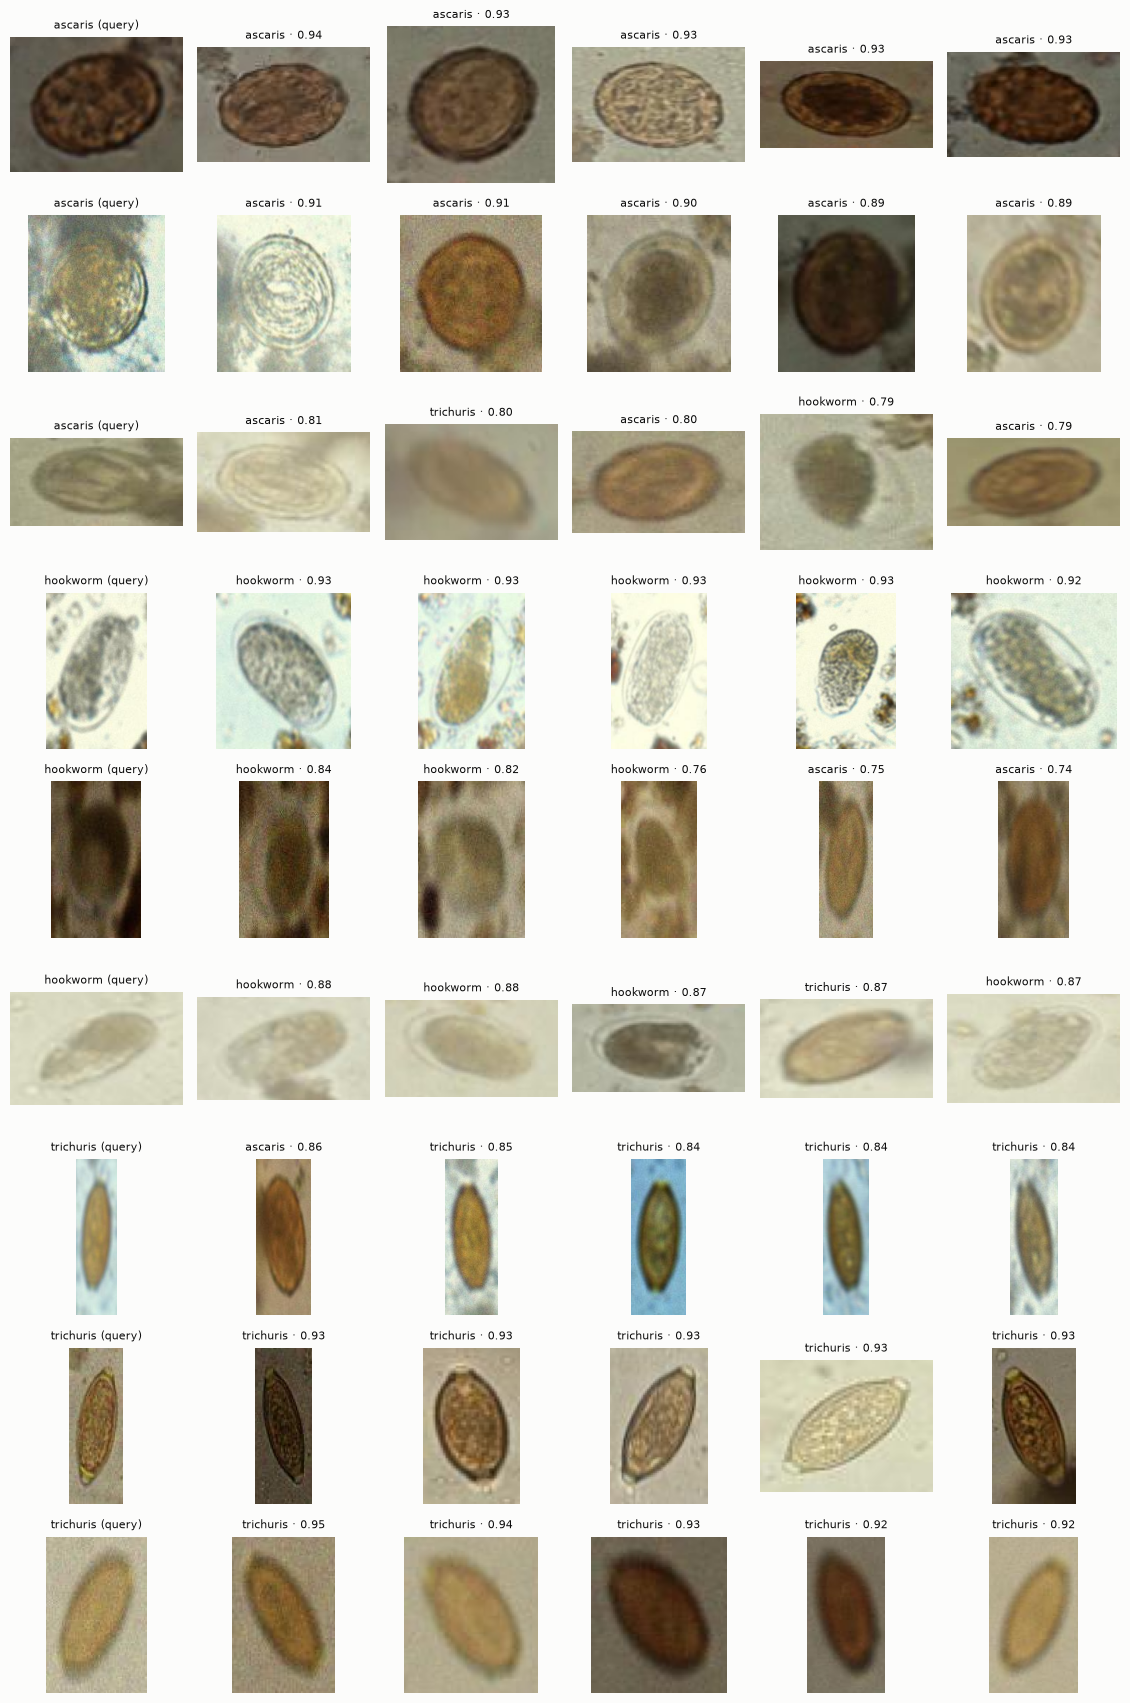

Crops whose 10 neighbors all belong to another species: 2 of 2337


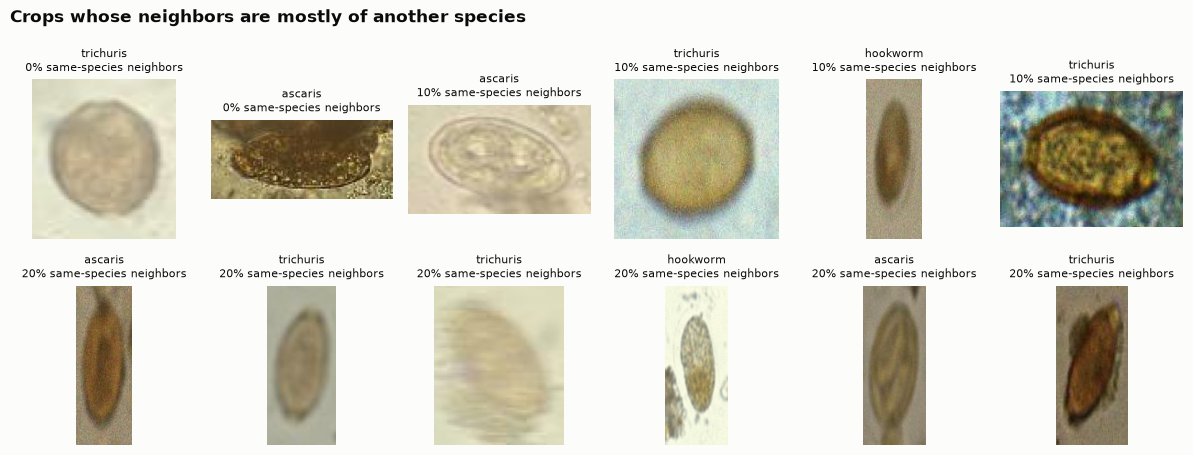

In [9]:
N_SHOWN_NEIGHBORS = 5
rng = np.random.default_rng(SEED)
queries = [index for name in CLASSES for index in rng.choice(np.flatnonzero(labels == name), 3, replace=False)]

fig, axes = plt.subplots(len(queries), N_SHOWN_NEIGHBORS + 1, figsize=(1.9 * (N_SHOWN_NEIGHBORS + 1), 1.9 * len(queries)))
for row, query in enumerate(queries):
    show_crop(axes[row, 0], crops.crop_path[query], f"{labels[query]} (query)")
    for col, neighbor in enumerate(np.argsort(-cls_similarity[query])[:N_SHOWN_NEIGHBORS], start=1):
        show_crop(axes[row, col], crops.crop_path[neighbor], f"{labels[neighbor]} · {cls_similarity[query, neighbor]:.2f}")
plt.tight_layout()
plt.show()

same_species_share = (labels[cls_neighbors] == labels[:, None]).mean(axis=1)
print(f"Crops whose {N_NEIGHBORS} neighbors all belong to another species: "
      f"{int((same_species_share == 0).sum())} of {len(crops)}")
odd_crops = (crops.assign(same_species_share=same_species_share)
             .sample(frac=1, random_state=SEED)
             .sort_values("same_species_share", kind="stable")
             .head(12))
fig, axes = plt.subplots(2, 6, figsize=(12, 4.6))
for ax, crop in zip(axes.ravel(), odd_crops.itertuples()):
    show_crop(ax, crop.crop_path, f"{crop.label}\n{crop.same_species_share:.0%} same-species neighbors")
fig.suptitle("Crops whose neighbors are mostly of another species", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

## 7. ¿El embedding guarda pistas que no son del huevo?

El EDA de las fotos encontró que el brillo, el color y el tamaño delataban la especie. Aquí se mira si esas
pistas viven dentro del embedding. Para cada recorte se miden, **sobre el propio recorte**: brillo medio,
contraste (desviación del gris), color (rojo medio − azul medio; positivo = amarillento) y tamaño de la caja
(lado mayor en píxeles de la foto). Después se calcula la correlación de Spearman entre cada uno de los primeros
componentes del PCA y esas medidas. Una correlación alta indica que esa dirección del espacio está ligada a una
condición de captura y no solo a la forma del huevo. El color de las celdas es el valor absoluto, y el número
lleva el signo.

Una correlación no prueba un atajo: el tamaño del huevo, por ejemplo, también es una característica real de
algunas especies.

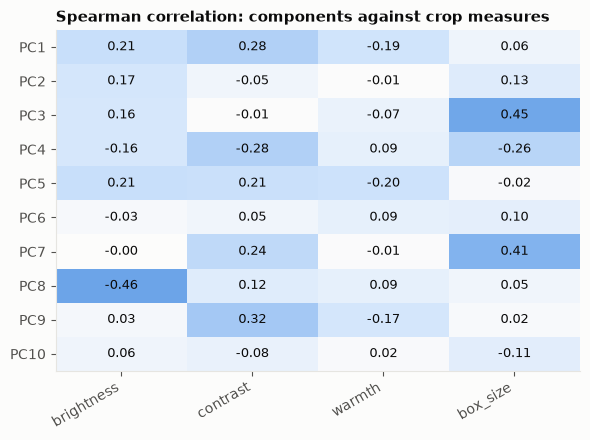

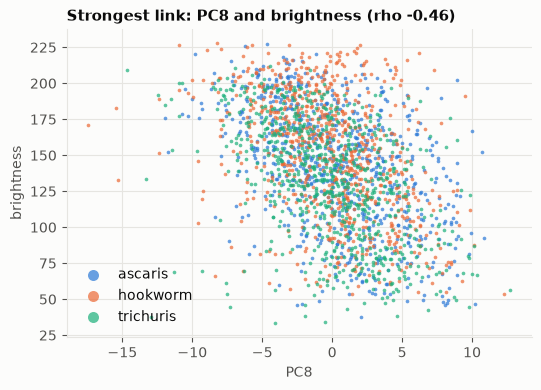

In [10]:
def crop_stats(crop_path):
    """Brightness, contrast and warmth measured on the crop itself."""
    rgb = np.asarray(Image.open(ROOT / crop_path).convert("RGB"), dtype=np.float32)
    gray = rgb.mean(axis=2)
    return {"brightness": gray.mean(), "contrast": gray.std(), "warmth": rgb[..., 0].mean() - rgb[..., 2].mean()}


pixel_stats = pd.DataFrame([crop_stats(path) for path in crops.crop_path])
pixel_stats["box_size"] = crops[["box_w", "box_h"]].max(axis=1).to_numpy()

component_names = [f"PC{number}" for number in range(1, N_COMPONENTS_SHOWN + 1)]
components_table = pd.DataFrame(cls_components[:, :N_COMPONENTS_SHOWN], columns=component_names)
correlation = (pd.concat([components_table, pixel_stats], axis=1)
               .corr(method="spearman")
               .loc[component_names, pixel_stats.columns])

fig, ax = plt.subplots(figsize=(6, 4.5))
draw_heatmap(ax, correlation.abs(), "Spearman correlation: components against crop measures",
             annotations=correlation, vmin=0, vmax=1)
plt.tight_layout()
plt.show()

# The strongest link, drawn with the species colors
strongest_component, strongest_measure = correlation.abs().stack().idxmax()
fig, ax = plt.subplots(figsize=(6, 4))
for name in CLASSES:
    mask = labels == name
    ax.scatter(components_table.loc[mask, strongest_component], pixel_stats.loc[mask, strongest_measure],
               s=7, color=COLORS[name], alpha=0.7, linewidths=0, label=name)
ax.set(xlabel=strongest_component, ylabel=strongest_measure,
       title=f"Strongest link: {strongest_component} and {strongest_measure} "
             f"(rho {correlation.loc[strongest_component, strongest_measure]:+.2f})")
ax.legend(markerscale=3)
plt.show()

## 8. `cls` contra `patch_mean`

Se guardaron dos formas de resumir una imagen con DINOv2. Se comparan con las mismas vistas: cuántos
componentes hacen falta para explicar el 90 % y el 95 % de la variación, y la pureza de los vecinos por especie.
No decide cuál usar el modelo: solo dice si se comportan distinto.

,components for 90%,components for 95%,purity ascaris,purity hookworm,purity trichuris
cls,151.0,253.0,0.923,0.944,0.917
patch_mean,101.0,187.0,0.843,0.886,0.839


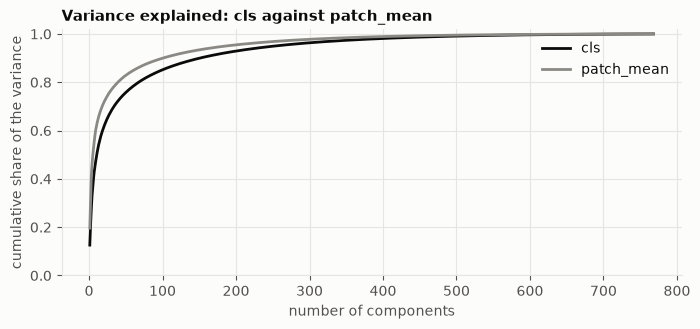

In [11]:
patch_mean_pca, _ = fit_pca(patch_mean_vectors)
patch_mean_neighbors, _ = nearest_neighbors(to_unit(patch_mean_vectors), N_NEIGHBORS)
patch_mean_neighbor_share = neighbor_share(patch_mean_neighbors)

versions = {"cls": (cls_pca, cls_neighbor_share), "patch_mean": (patch_mean_pca, patch_mean_neighbor_share)}
comparison = pd.DataFrame({
    name: {
        "components for 90%": components_needed(pca, 0.90),
        "components for 95%": components_needed(pca, 0.95),
        **{f"purity {species}": share.loc[species, species] for species in CLASSES},
    }
    for name, (pca, share) in versions.items()
}).T
display(comparison.round(3))

fig, ax = plt.subplots(figsize=(8, 3.2))
for (name, (pca, _)), color in zip(versions.items(), (INK, MUTED)):
    ax.plot(np.arange(1, len(pca.explained_variance_ratio_) + 1), np.cumsum(pca.explained_variance_ratio_),
            color=color, linewidth=2, label=name)
ax.set(title="Variance explained: cls against patch_mean", xlabel="number of components",
       ylabel="cumulative share of the variance", ylim=(0, 1.02))
ax.legend()
plt.show()

## 9. Contraste con los recortes de YOLO

El detector se corrió sobre `valid` y sus cajas se recortaron igual que las dibujadas a mano: 425 recortes, de
los cuales 412 coinciden con un huevo real y 13 son **falsas alarmas** (cajas donde no hay huevo). Para cada uno
se mide la similitud con su recorte más parecido de `train`. Si los recortes de YOLO que sí son huevos quedan
tan cerca de `train` como los dibujados a mano, el detector no cambia lo que ve el clasificador. Si las falsas
alarmas quedan lejos de todo, ahí hay una señal para rechazarlas ("consulte a un experto").

{'hookworm': 140, 'trichuris': 137, 'ascaris': 135, 'none': 13}


,count,mean,std,min,25%,50%,75%,max
group,,,,,,,,
Hand-drawn box,413.0,0.904,0.053,0.641,0.886,0.919,0.939,0.978
"YOLO box, egg",412.0,0.904,0.053,0.663,0.885,0.919,0.939,0.977
"YOLO box, false alarm",13.0,0.810,0.113,0.568,0.738,0.861,0.889,0.906


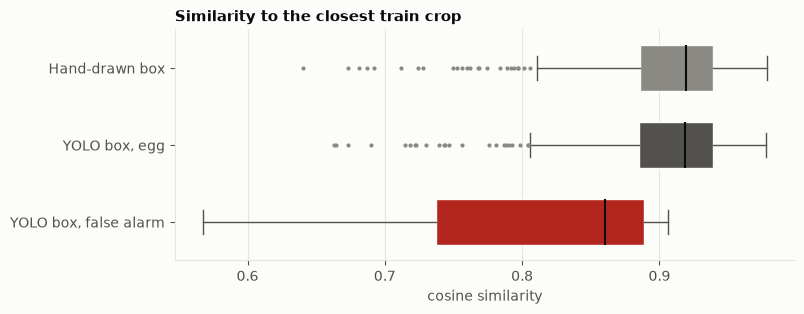

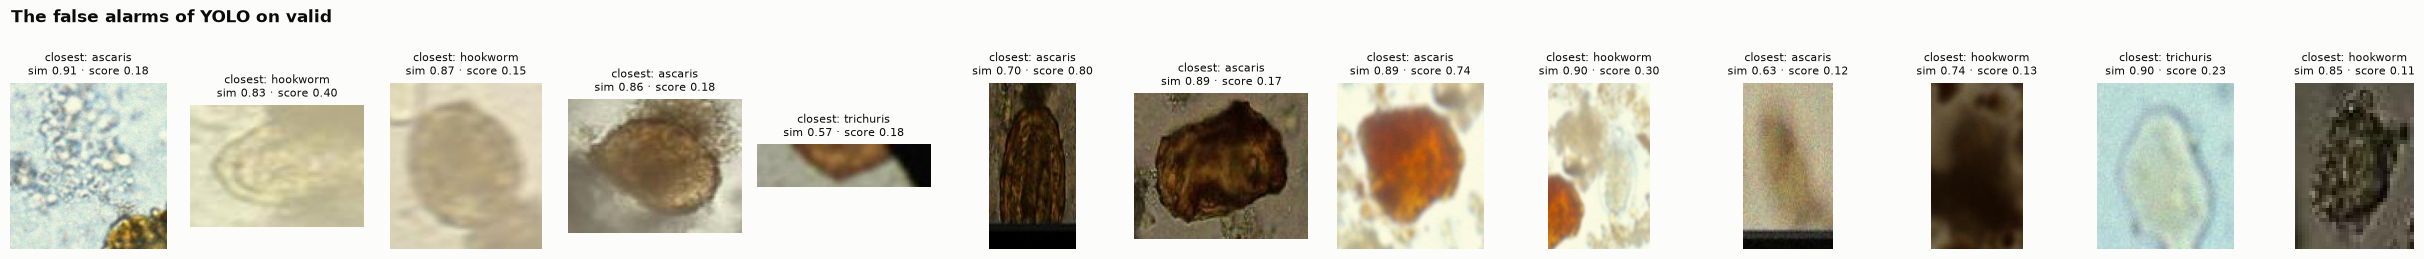

In [12]:
yolo_crops, yolo_cls, _ = load_embeddings(YOLO_EMBEDDINGS_NPZ, YOLO_CROPS_CSV)
similarity_to_train = to_unit(yolo_cls) @ unit_cls[is_train].T
yolo_closest_similarity = similarity_to_train.max(axis=1)
yolo_closest_species = labels[is_train][similarity_to_train.argmax(axis=1)]
yolo_group = np.where(yolo_crops.label == "none", "YOLO box, false alarm", "YOLO box, egg")
print(yolo_crops.label.value_counts().to_dict())

similarity_by_group = pd.concat([
    pd.DataFrame({"group": "Hand-drawn box", "similarity": closest_similarity}),
    pd.DataFrame({"group": yolo_group, "similarity": yolo_closest_similarity}),
])
display(similarity_by_group.groupby("group").similarity.describe().loc[list(YOLO_GROUP_COLORS)].round(3))

fig, ax = plt.subplots(figsize=(8, 3))
box_plot = ax.boxplot(
    [similarity_by_group.loc[similarity_by_group.group == name, "similarity"] for name in YOLO_GROUP_COLORS],
    orientation="horizontal", patch_artist=True, widths=0.6,
    medianprops={"color": INK, "linewidth": 1.5},
    flierprops={"marker": "o", "markersize": 3, "markerfacecolor": MUTED, "markeredgecolor": "none"},
    whiskerprops={"color": INK2}, capprops={"color": INK2},
)
for patch, color in zip(box_plot["boxes"], YOLO_GROUP_COLORS.values()):
    patch.set(facecolor=color, edgecolor=SURFACE)
ax.set_yticks([1, 2, 3], list(YOLO_GROUP_COLORS))
ax.invert_yaxis()
ax.set(title="Similarity to the closest train crop", xlabel="cosine similarity")
ax.grid(axis="y", visible=False)
plt.show()

# The false alarms themselves, with the species of their closest train crop
false_alarms = yolo_crops[yolo_crops.label == "none"]
fig, axes = plt.subplots(1, len(false_alarms), figsize=(1.9 * len(false_alarms), 2.6), squeeze=False)
for ax, (index, crop) in zip(axes[0], false_alarms.iterrows()):
    show_crop(ax, crop.crop_path,
              f"closest: {yolo_closest_species[index]}\nsim {yolo_closest_similarity[index]:.2f} · score {crop.det_conf:.2f}")
fig.suptitle("The false alarms of YOLO on valid", x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

## 10. Conclusiones

Se escriben al final, con los números de arriba.